# US 01 · Data and point-in-time S&P 1500-style universe

This repeats the ASX data pipeline (`../01_data_and_universe.ipynb`) for **US equities**, so the channel-breakout research can be re-run on a second market.

1. Build a ticker pool: today's S&P 500, MidCap 400 and SmallCap 600 members, plus stocks *removed* from the 400 and 600 that still have Yahoo data.
2. Download daily OHLCV and benchmarks (S&P 500 and the 400/600 indices).
3. Clean returns with the same rules as the ASX study.
4. Build a point-in-time universe: each month end, the **1,500 most-traded eligible stocks** in the pool.

**Survivorship bias is worse here than for the ASX.** For the ASX the pool was every currently listed company. Here it is index members, which is a narrower group of survivors. Adding the removed-from-index names that still trade softens this, because those are often stocks that shrank, but bankrupt and acquired companies are still missing. Alpha is again measured against an equal-weight universe with the same bias.

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf

pd.set_option("display.width", 200)
DATA = Path("data")
DATA.mkdir(exist_ok=True)

START = "2005-01-01"
BENCHMARKS = ["^GSPC", "^SP400", "^SP600"]
N_UNIVERSE = 1500
MIN_PRICE = 5.0          # US convention: exclude sub-$5 stocks
MIN_HISTORY = 252
SPIKE = np.log(1.5)
WIKI = {"S&P 500": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
        "S&P 400": "https://en.wikipedia.org/wiki/List_of_S%26P_400_companies",
        "S&P 600": "https://en.wikipedia.org/wiki/List_of_S%26P_600_companies"}

## 1. Ticker pool

Wikipedia lists the current members of each index and, for the 400 and 600, a table of past additions and removals. Yahoo writes share-class tickers with a dash (`BRK-B`, not `BRK.B`).

In [2]:
def wiki_tables(url):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (research)"}, timeout=30)
    r.raise_for_status()
    return pd.read_html(io.StringIO(r.text))


pool_path = DATA / "ticker_pool.csv"
if not pool_path.exists():
    rows = []
    for index, url in WIKI.items():
        tables = wiki_tables(url)
        cur = tables[0]
        rows += [{"ticker": s, "sector": g, "source": f"{index} current"}
                 for s, g in zip(cur["Symbol"], cur["GICS Sector"])]
        for t in tables[1:]:
            if isinstance(t.columns, pd.MultiIndex) and ("Removed", "Ticker") in t.columns:
                rows += [{"ticker": s, "sector": None, "source": f"{index} removed"}
                         for s in t[("Removed", "Ticker")].dropna()]
    pool = pd.DataFrame(rows)
    pool["ticker"] = pool["ticker"].astype(str).str.strip().str.replace(".", "-", regex=False)
    pool = pool[pool["ticker"].str.fullmatch(r"[A-Z][A-Z0-9\-]{0,6}")]
    # a ticker that is a current member keeps that label
    pool["current"] = pool["source"].str.endswith("current")
    pool = pool.sort_values("current", ascending=False).drop_duplicates("ticker")
    pool.to_csv(pool_path, index=False)
pool = pd.read_csv(pool_path)
pool["source"].value_counts()

source
S&P 600 current    603
S&P 500 current    503
S&P 600 removed    402
S&P 400 current    397
S&P 400 removed    245
Name: count, dtype: int64

## 2. Download

In [3]:
def download(tickers, batch=200):
    frames = []
    for i in range(0, len(tickers), batch):
        chunk = tickers[i:i + batch]
        for attempt in range(3):
            try:
                d = yf.download(chunk, start=START, auto_adjust=False, actions=False,
                                progress=False, threads=True, group_by="column")
                break
            except Exception as e:
                print("retry", i, e)
                time.sleep(5)
        d = d.stack(level=1, future_stack=True).rename_axis(["date", "ticker"])
        frames.append(d.dropna(how="all"))
        print(f"{i + len(chunk)}/{len(tickers)}")
    out = pd.concat(frames)
    out.columns = [c.lower().replace(" ", "_") for c in out.columns]
    return out


if not (DATA / "ohlcv.parquet").exists():
    download(sorted(pool["ticker"])).to_parquet(DATA / "ohlcv.parquet")
    download(BENCHMARKS).to_parquet(DATA / "benchmarks.parquet")
raw = pd.read_parquet(DATA / "ohlcv.parquet")
got = set(raw.index.get_level_values("ticker"))
print(f"{len(got)} of {len(pool)} tickers have Yahoo data")
pool.assign(has_data=pool["ticker"].isin(got)).groupby("source")["has_data"].agg(["sum", "count"])

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: APOL"}}}


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: AGP"}}}



44 Failed downloads:


['ARRS', 'APOL', 'ASGN', 'AGP', 'ACOR', 'ADVS', 'AINV', 'AIRC', 'AMBC', 'ALTM', 'ATW', 'APLS', 'AVID', 'AGTI', 'AMAG', 'AMED', 'ABTX', 'ACC', 'ANR', 'AHL', 'ANSS', 'AVP', 'AL', 'AAWW', 'AOL', 'ATGE', 'AEL', 'ALE', 'AJRD', 'ASNA', 'ALEX', 'ADS', 'AAN', 'AVTA', 'ARCH', 'AMWD', 'AVNS', 'AMSG', 'ABMD', 'ALTR', 'ATML', 'ARNC', 'AKRX', 'AEGN']: YFTzMissingError('possibly delisted; no timezone found')


200/2150


...

['WSR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2005-01-01 -> 2026-10-10)')


2150/2150


3/3


1718 of 2150 tickers have Yahoo data


,sum,count
source,,
S&P 400 current,397,397
S&P 400 removed,29,245
S&P 500 current,503,503
S&P 600 current,602,603
S&P 600 removed,187,402


Most current members have data. Only part of the removed names do: the rest were acquired or went bankrupt and Yahoo no longer serves them, which is exactly the survivorship gap. A further catch: US tickers get reused, so a removed ticker that does have data may now belong to a *different* company. Those series are still real stocks, but they don't fill the survivorship gap as cleanly as the count suggests.

## 3. Cleaning

The rules are the same as for the ASX (see the ASX notebook 01 for the reasoning):
* broken adjustment factors (a big adjusted move the raw close doesn't share) are masked;
* bad prints (a jump of more than 50% that mostly reverses the next day) are masked on both days;
* moves beyond +400% or −80% in a day are masked;
* returns on stale (zero-volume) days are masked;
* high and low are put on the adjusted scale and forced to bracket the close.

In [4]:
def clean_returns(adj, close):
    lr = np.log(adj).diff()
    raw_lr = np.log(close).diff()
    lr = lr.mask((lr.abs() > SPIKE) & ((lr - raw_lr).abs() > SPIKE))
    nxt = lr.shift(-1)
    spike = (lr.abs() > SPIKE) & (np.sign(lr) == -np.sign(nxt)) & (nxt.abs() > 0.7 * lr.abs())
    lr = lr.mask(spike | spike.shift(1, fill_value=False))
    lr = lr.mask(lr.abs() > np.log(5))
    return np.expm1(lr)


wide = {c: raw[c].unstack() for c in ["adj_close", "close", "high", "low", "volume"]}
close = wide["close"].where(wide["close"] > 0)
adj = wide["adj_close"].where(wide["adj_close"] > 0)
factor = adj / close
high = np.maximum(wide["high"].where(wide["high"] > 0) * factor, adj)
low = np.minimum(wide["low"].where(wide["low"] > 0) * factor, adj)
vol = wide["volume"].fillna(0)
traded = vol > 0
ret = clean_returns(adj, close).where(traded | traded.shift(1, fill_value=False))
masked = int((ret.isna() & adj.notna() & adj.shift(1).notna()).sum().sum())
print(f"{adj.shape[1]} stocks, {adj.shape[0]} days; returns masked by cleaning: {masked:,}")

1718 stocks, 5477 days; returns masked by cleaning: 20,648


## 4. Point-in-time universe

At each month end, a stock is eligible if it has at least 252 days of history, a raw close of at least \$5, and a 63-day median traded value (needing at least 40 traded days). The top 1,500 by traded value are members for the following month.

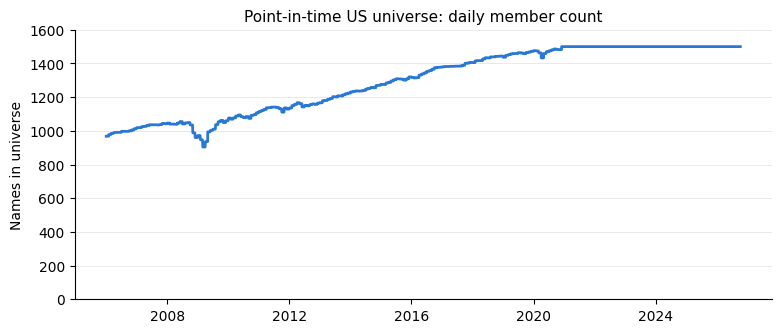

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
avg members,993.0,1032.0,1032.0,1003.0,1085.0,1131.0,1154.0,1199.0,1248.0,1298.0,...,1389.0,1430.0,1459.0,1474.0,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0


In [5]:
dollar_vol = (close * vol).where(traded)
adv = dollar_vol.rolling(63, min_periods=40).median()
history = adj.notna().cumsum()
month_end = adj.index.to_series().groupby(adj.index.to_period("M")).max()
elig = (history >= MIN_HISTORY) & (close >= MIN_PRICE) & adv.notna()
rank = adv.where(elig).loc[month_end.values].rank(axis=1, ascending=False)
member = (rank <= N_UNIVERSE).reindex(adj.index).shift(1)
member = member.astype("float").ffill().fillna(0).astype(bool)

counts = member.sum(axis=1).loc["2006":]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(counts.index, counts.values, color="#2a78d6", lw=2)
ax.set_ylim(0, 1600)
ax.set_ylabel("Names in universe")
ax.set_title("Point-in-time US universe: daily member count", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
plt.show()
counts.groupby(counts.index.year).mean().round(0).to_frame("avg members").T

The count climbs over time for the same reason as on the ASX: fewer of today's survivors existed, or were big and liquid enough, in earlier years.

## 5. Benchmarks and save

In [6]:
sector = pool.set_index("ticker")["sector"]
bench = pd.read_parquet(DATA / "benchmarks.parquet")["adj_close"].unstack()
bench_ret = bench.pct_change(fill_method=None).reindex(adj.index)
d = dict(adj=adj, high=high, low=low, close=close, volume=vol, ret=ret, adv=adv,
         member=member, sector=sector.reindex(adj.columns), bench_ret=bench_ret)
pd.to_pickle(d, DATA / "clean.pkl")
print(f"members ever: {member.any().sum()}; benchmarks: {list(bench_ret.columns)}")

members ever: 1675; benchmarks: ['^GSPC', '^SP400', '^SP600']
